# Notebook A：軸対称円盤の質量積分と回転曲線

**Ryden, *Celestial and Stellar Dynamics*, §6.5**

テキスト付録Aに対応する Notebook です。薄い軸対称円盤を題材に、第1章で学んだ数値積分を別の問題へ適用します。球殻から円環へ質量要素を変え、同じ累積台形則で内包質量を求めます。指数円盤の解析解との比較と格子収束試験によって、実装を再利用した場合も精度を検証します。

後半では、円盤と球対称近似の回転曲線を比較します。ここでは解析式を用い、数値積分の誤差を混ぜずに、質量分布の仮定による違いを調べます。

## 学習目標

- 軸対称円盤の質量を求める問題について、数値積分の被積分関数と積分区間を設定できる。
- 被積分関数を入れ替え、第1章の累積台形則の実装を別の質量分布に再利用できる。
- 解析解との比較と格子収束試験から、累積積分の誤差と収束次数を評価できる。
- 数値積分の離散化誤差と、有限の計算領域の外にある質量を区別できる。
- 数値計算の誤差と、物理モデルの仮定によって生じる違いを区別できる。

第1章の数値積分が前提です。第2・3章や他の付録を先に読む必要はなく、本編の基礎学習や付録Cの軌道計算に進むための必須事項でもありません。積分公式と累積積分は、テキスト第1章と幸谷『Python数値計算プログラミング』第12章を参照してください。

## 実行順序とテキストとの対応

この Notebook は単独で、上から順に実行できます。他の Notebook の実行結果は必要ありません。設定を変更した場合は、カーネルを再起動して全セルを実行してください。$G$ は準備セル、$M_d$ と $R_d$ は関数定義のセルで設定します。

| テキスト付録A | この Notebook の節名 |
|---|---|
| 球対称系と軸対称円盤の質量要素 | 球対称系と軸対称円盤の質量要素 |
| 指数円盤の内包質量 | 指数円盤 |
| 累積台形則による数値積分 | 内包質量の数値積分 |
| 累積台形則の格子収束 | 累積台形則の格子収束 |
| 指数円盤の回転曲線と球対称近似 | 円盤の重力と球対称近似／指数円盤と Mestel 円盤の回転曲線 |
| Mestel 円盤と平坦な回転曲線 | 指数円盤と Mestel 円盤の回転曲線 |

本文の Listing A.1 は面密度と被積分関数を返す関数、Notebook block はそれらを使う数値実験の主要部分です。この Notebook には、完全な関数定義、作図、出力、追加演習を収録しています。

回転曲線は修正 Bessel 関数による解析式を評価します。Hankel 積分を直接数値積分する方法は、末尾の演習4に置いた発展課題です。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

G = 1.0

OI = {
    "orange": "#E69F00",
    "sky": "#56B4E9",
    "green": "#009E73",
    "yellow": "#F0E442",
    "blue": "#0072B2",
    "vermillion": "#D55E00",
    "purple": "#CC79A7",
    "black": "#000000",
}

plt.rcParams["figure.figsize"] = (6.5, 4.5)
plt.rcParams["font.size"] = 11


# 1. 球対称系と軸対称円盤の質量要素

第1章の球対称系では、球殻の質量要素は
$$
dM = 4\pi r^2\rho(r)\,dr
$$
でした。一方、無限に薄い軸対称円盤では、円盤面内の半径を $R$、単位面積あたりの質量である面密度（surface density）を $\Sigma(R)$ とします。半径 $R$、幅 $dR$ の円環（annulus）の面積は $dA=2\pi R\,dR$ なので、
$$
dM=2\pi R\Sigma(R)\,dR
$$
となります。半径 $R$ より内側の内包質量は
$$
\boxed{M(<R)=\int_0^R 2\pi R'\Sigma(R')\,dR'}
$$
です。$R'$ は積分変数です。

数値積分に渡す被積分関数は $\Sigma(R')$ そのものではなく、$f_M(R')=2\pi R'\Sigma(R')$、積分区間は $[0,R]$ です。球対称系の $4\pi r'^2\rho(r')$ をこの関数に入れ替えれば、第1章と同じ積分法を使えます。

# 2. 指数円盤

Ryden 式(6.160) の指数円盤
$$
\Sigma(R)=\Sigma_0 e^{-R/R_d}
$$
を使います。$\Sigma_0$ は中心面密度、$R_d$ は面密度が中心値の $1/e$ になる半径です。

## 全質量と中心面密度

全質量を $M_d$ とし、$u=R'/R_d$ と変数変換すると、
$$
M_d=2\pi\Sigma_0\int_0^\infty R'e^{-R'/R_d}\,dR'=2\pi\Sigma_0R_d^2\int_0^\infty ue^{-u}\,du
$$
です。部分積分から
$$
\int ue^{-u}\,du=-ue^{-u}+\int e^{-u}\,du=-(u+1)e^{-u}+C
$$
なので、定積分の値は1です。したがって、
$$
M_d=2\pi\Sigma_0R_d^2,\qquad \Sigma_0=\frac{M_d}{2\pi R_d^2}
$$
となります。次のセルでは $M_d$ と $R_d$ を指定して $\Sigma_0$ を決めます。

## 内包質量の解析解

有限半径まで同じ積分を行うと、
$$
M(<R)=2\pi\Sigma_0R_d^2\int_0^{R/R_d}ue^{-u}\,du
$$
から、Ryden 式(6.161) の解析解
$$
\boxed{M(<R)=M_d\left[1-e^{-R/R_d}\left(1+\frac{R}{R_d}\right)\right]}
$$
を得ます。$R=0$ で0、$R\to\infty$ で $M_d$ となります。この解析解を、有限半径までの数値積分を検証する基準にします。

## 被積分関数と実装

被積分関数は
$$
f_M(R)=\frac{dM}{dR}=2\pi R\Sigma(R)=\frac{M_d}{R_d}\frac{R}{R_d}e^{-R/R_d}
$$
です。`sigma_exponential` が面密度、`dMdR_exponential` が被積分関数、`mass_exponential_exact` が内包質量の解析解を返します。`cumulative_trapezoid_manual` は第1章と同じ累積台形則です。

面密度は中心で最大ですが、$dM/dR$ は中心で0です。次の図では、面密度を $\Sigma_0$、被積分関数を $M_d/R_d$ で割り、半径に対する形の違いを確認します。

In [2]:
Md = 1.0
Rd = 1.0
Sigma0 = Md / (2.0 * np.pi * Rd**2)

def sigma_exponential(R, Md=1.0, Rd=1.0):
    Sigma0 = Md / (2.0 * np.pi * Rd**2)
    return Sigma0 * np.exp(-R / Rd)

def dMdR_exponential(R, Md=1.0, Rd=1.0):
    return 2.0 * np.pi * R * sigma_exponential(R, Md, Rd)

def mass_exponential_exact(R, Md=1.0, Rd=1.0):
    x = R / Rd
    return Md * (1.0 - np.exp(-x) * (1.0 + x))

def cumulative_trapezoid_manual(x, y):
    """台形則で y(x) の累積積分を求める（配列操作は Notebook 1 を参照）。"""
    result = np.zeros_like(x, dtype=float)
    dx = np.diff(x)
    area = 0.5 * (y[:-1] + y[1:]) * dx
    result[1:] = np.cumsum(area)
    return result


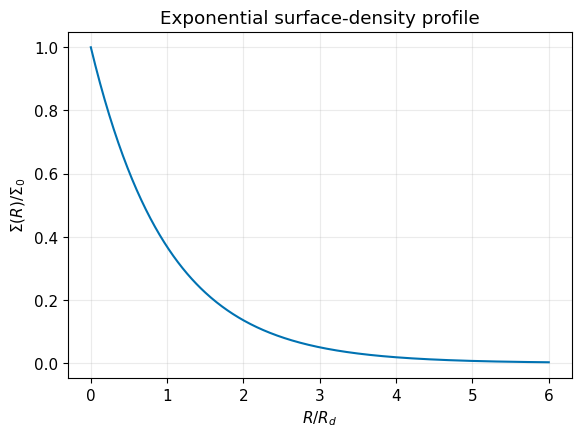

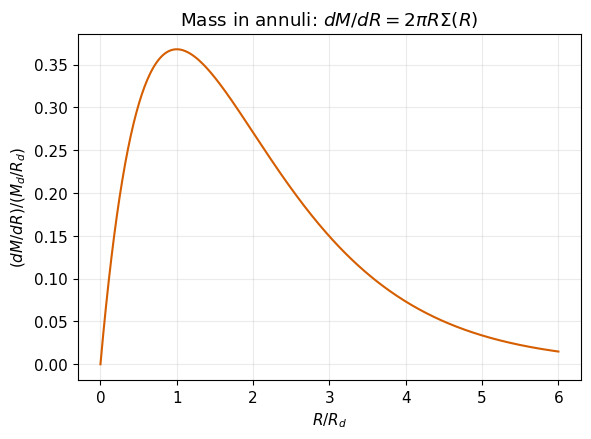

In [3]:
R_plot = np.linspace(0.0, 6.0 * Rd, 500)
Sigma_plot = sigma_exponential(R_plot, Md, Rd)
dMdR_plot = dMdR_exponential(R_plot, Md, Rd)

fig, ax = plt.subplots()
ax.plot(R_plot / Rd, Sigma_plot / Sigma0, color=OI["blue"])
ax.set_xlabel(r"$R/R_d$")
ax.set_ylabel(r"$\Sigma(R)/\Sigma_0$")
ax.set_title("Exponential surface-density profile")
ax.grid(alpha=0.25)
plt.show()

fig, ax = plt.subplots()
ax.plot(R_plot / Rd, dMdR_plot / (Md / Rd), color=OI["vermillion"])
ax.set_xlabel(r"$R/R_d$")
ax.set_ylabel(r"$(dM/dR)/(M_d/R_d)$")
ax.set_title(r"Mass in annuli: $dM/dR = 2\pi R\Sigma(R)$")
ax.grid(alpha=0.25)
plt.show()



## 演習1：円盤の幾何

1. $\Sigma(R)$ は中心から単調に減少しますが、$dM/dR$ は $R=0$ で0です。なぜでしょうか。
2. $dM/dR$ が最大になる半径を、解析的または数値的に求めてください。
3. 球対称系の $4\pi r^2\rho(r)$ と、円盤の $2\pi R\Sigma(R)$ の役割を比較してください。


# 3. 内包質量の数値積分

第1章と同じ累積台形則を、$f_M(R)=2\pi R\Sigma(R)$ に適用します。計算領域を $0\le R\le R_{\max}$ とし、$N$ 個の区間、$N+1$ 個の格子点に分けます。
$$
R_i=i\Delta R,\qquad \Delta R=\frac{R_{\max}}{N},\qquad i=0,1,\ldots,N.
$$
内包質量の数値近似 $M_i$ は、
$$
M_0=0,\qquad M_{i+1}=M_i+\frac{\Delta R}{2}\left[f_M(R_i)+f_M(R_{i+1})\right]
$$
として外側へ順に求めます。各半径について0から積分をやり直す必要はありません。積分公式と配列演算の対応は、テキスト第1章「累積積分による内包質量プロファイル」を参照してください。

ここでは $R_{\max}=10R_d$、$N=400$ とします。数値解と同じ格子点で解析解を評価し、比較します。

**二つの差を区別する：** 数値解と同じ上端までの解析解との差は積分の誤差です。一方、$M_d-M_{\rm exact}(<R_{\max})$ は計算領域の外にある質量で、有限区間の積分そのものの誤差ではありません。$R_{\max}$ を固定したまま格子を細かくしても、後者は変わりません。以下では両者を $M_d$ で規格化して表示します。

In [4]:
# 0 <= R <= 10 Rd を N=400 区間に分ける
N = 400
R_max = 10.0 * Rd
R = np.linspace(0.0, R_max, N + 1)

# 被積分関数 dM/dR = 2 pi R Sigma(R) を格子点で評価する
dMdR = dMdR_exponential(R, Md, Rd)

# 累積台形則と、同じ格子点での解析解を比較する
M_num = cumulative_trapezoid_manual(R, dMdR)
M_exact = mass_exponential_exact(R, Md, Rd)

# 積分誤差と、計算領域の外にある質量を別々に測る
mass_error_outer = (M_num[-1] - M_exact[-1]) / Md
mass_outside = (Md - M_exact[-1]) / Md

print(f"M_num(<R_max)   = {M_num[-1]:.10f}")
print(f"M_exact(<R_max) = {M_exact[-1]:.10f}")
print(f"円盤の全質量 = {Md:.10f}")
print(f"外端での符号付き積分誤差 / Md = {mass_error_outer:.6e}")
print(f"計算領域の外にある質量 / Md = {mass_outside:.6e}")

M_num(<R_max)   = 0.9994484978
M_exact(<R_max) = 0.9995006008
円盤の全質量 = 1.0000000000
外端での符号付き積分誤差 / Md = -5.210299e-05
計算領域の外にある質量 / Md = 4.993992e-04


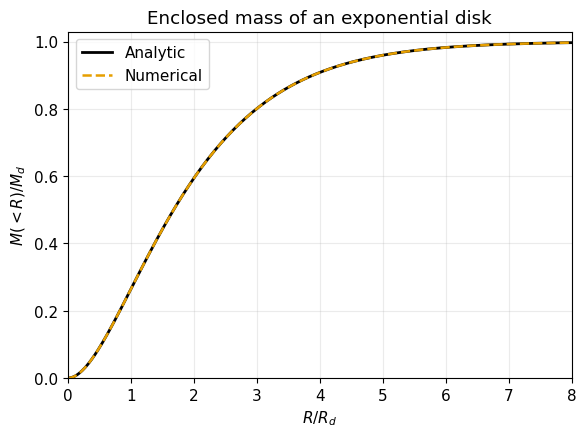

In [5]:
fig, ax = plt.subplots()
ax.plot(R / Rd, M_exact / Md, color=OI["black"], lw=2.0, label="Analytic")
ax.plot(R / Rd, M_num / Md, "--", color=OI["orange"], lw=1.8, label="Numerical")
ax.set_xlabel(r"$R/R_d$")
ax.set_ylabel(r"$M(<R)/M_d$")
ax.set_title("Enclosed mass of an exponential disk")
ax.set_xlim(0, 8)
ax.set_ylim(0, 1.03)
ax.legend()
ax.grid(alpha=0.25)
plt.show()


## 演習2：内包質量と計算領域

1. $R=R_d$, $2R_d$, $3R_d$, $5R_d$ の内側に全質量の何%が含まれるか、解析解を用いて求めてください。
2. $R_{\max}$ を固定して格子を細かくし、外端での積分誤差が減少する一方、計算領域の外にある質量は変わらないことを確認してください。
3. 次に格子幅 $\Delta R$ を固定して $R_{\max}$ を増やし、$M_{\rm exact}(<R_{\max})$ が $M_d$ に近づくことを確認してください。$R_{\max}$ に合わせて区間数 $N$ も増やします。
4. 数値解と解析解の差が、どの半径で大きくなるか調べてください。

# 4. 累積台形則の格子収束

計算領域 $R_{\max}=10R_d$ と $M_d,R_d$ を固定し、区間数 $N$ だけを変えます。全格子点での誤差を
$$
\epsilon_M=\max_{0\le i\le N}\frac{|M_{\rm num}(<R_i)-M_{\rm exact}(<R_i)|}{M_d}
$$
で測ります。これは全質量で規格化した最大絶対誤差であり、各点の内包質量に対する相対誤差ではありません。この規格化なら、内包質量が0の中心も評価に含められます。

第1章で学んだ台形則の誤差評価から、滑らかな被積分関数を固定区間で積分すると、離散化誤差が支配する範囲では
$$
\epsilon_M\simeq C\left(\frac{\Delta R}{R_d}\right)^p,\qquad p=2
$$
が期待されます。$R_d$ は固定しているので、コードで使う $\log\Delta R$ に対する $\log\epsilon_M$ の傾きも $p$ です。

$N=25,50,100,200,400,800$ の6格子で計算し、誤差が規則的に減少することを確かめてから傾きを求めます。格子数をさらに増やす場合は、丸め誤差で停滞した点や誤差が0になった点を当てはめに含めないでください。

In [6]:
# 1つの格子で内包質量の最大誤差を測る
def exponential_mass_error(N, R_max=10.0, Md=1.0, Rd=1.0):
    R = np.linspace(0.0, R_max, N + 1)
    dMdR = dMdR_exponential(R, Md, Rd)
    M_num = cumulative_trapezoid_manual(R, dMdR)
    M_exact = mass_exponential_exact(R, Md, Rd)
    dR = R[1] - R[0]
    err = np.max(np.abs(M_num - M_exact)) / Md
    return dR, err

# 領域とモデルを固定し、区間数を2倍ずつ増やす
N_values = np.array([25, 50, 100, 200, 400, 800])
dR_values = []
mass_errors = []
for N_i in N_values:
    dR_i, err_i = exponential_mass_error(int(N_i), 10.0 * Rd, Md, Rd)
    dR_values.append(dR_i)
    mass_errors.append(err_i)

dR_values = np.array(dR_values)
mass_errors = np.array(mass_errors)

# log(error)-log(dR) の直線の傾きが収束次数 p
order_mass = np.polyfit(np.log(dR_values), np.log(mass_errors), 1)[0]

for N_i, dR_i, err_i in zip(N_values, dR_values, mass_errors):
    print(f"N = {N_i:4d}, dR = {dR_i:.6e}, 誤差 = {err_i:.6e}")

print(f"\n測定した収束次数 = {order_mass:.3f}")

N =   25, dR = 4.000000e-01, 誤差 = 1.503657e-02
N =   50, dR = 2.000000e-01, 誤差 = 3.778095e-03
N =  100, dR = 1.000000e-01, 誤差 = 9.457150e-04
N =  200, dR = 5.000000e-02, 誤差 = 2.365033e-04
N =  400, dR = 2.500000e-02, 誤差 = 5.913049e-05
N =  800, dR = 1.250000e-02, 誤差 = 1.478291e-05

測定した収束次数 = 1.998


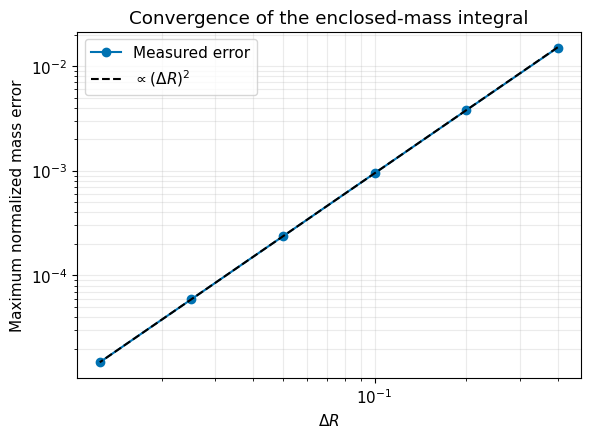

In [7]:
reference = mass_errors[-1] * (dR_values / dR_values[-1])**2

fig, ax = plt.subplots()
ax.loglog(dR_values, mass_errors, "o-", color=OI["blue"], label="Measured error")
ax.loglog(dR_values, reference, "--", color=OI["black"], label=r"$\propto(\Delta R)^2$")
ax.set_xlabel(r"$\Delta R$")
ax.set_ylabel("Maximum normalized mass error")
ax.set_title("Convergence of the enclosed-mass integral")
ax.legend()
ax.grid(alpha=0.25, which="both")
plt.show()



## 演習3：収束性

1. 測定した収束次数が2に近いことを確認してください。
2. 最も粗い格子を除いて収束次数を再計算してください。
3. Notebook 1 の Plummer 球と比較し、同じ台形則でも被積分関数が変わると誤差係数が変わることを確認してください。


# 5. 円盤の重力と球対称近似

ここまでは数値積分の誤差を調べました。次に、**数値手法の再利用と、物理の関係式をそのまま使うことは別である**と確認します。

球対称系では Newton の球殻定理により、
$$
v_{\rm circ}^2(r)=\frac{GM(<r)}{r}
$$
です。しかし、円盤面内の重力には $R$ より外側の質量も寄与するため、その半径より内側の総質量だけでは円運動速度を決められません。

Ryden 式(6.145) では、面密度の Hankel 変換を
$$
S(k)=\int_0^\infty\Sigma(R')J_0(kR')R'\,dR'
$$
と定めています。これを使うと、式(6.149) の円運動速度は
$$
v_{\rm circ}^2(R)=2\pi GR\int_0^\infty S(k)J_1(kR)k\,dk
$$
と表されます。$J_0$ と $J_1$ は第1種 Bessel 関数、$k$ は長さの逆数の次元を持つ積分変数です。

この積分表示は、円盤全体の面密度が重力場に関係することを示しています。ここでは Hankel 積分を直接計算せず、次節の指数円盤の解析式を使います。直接数値積分する方法は、演習4の発展課題です。

# 6. 指数円盤と Mestel 円盤の回転曲線

薄い指数円盤 $\Sigma(R)=\Sigma_0e^{-R/R_d}$ の回転曲線は、修正 Bessel 関数（modified Bessel functions）を用いて
$$
v_{\rm disk}^2(R)=4\pi G\Sigma_0R_d\,y^2\left[I_0(y)K_0(y)-I_1(y)K_1(y)\right],\qquad y=\frac{R}{2R_d}
$$
と書けます。$I_n$ と $K_n$ は第1種・第2種の $n$ 次修正 Bessel 関数です。この式は、Ryden 式(6.149) の Hankel 積分を指数円盤について評価した形です。Ryden 本文にはこの修正 Bessel 関数による式自体は書かれていませんが、図6.6に円盤の回転曲線が示されています。

ここではこの式を導出せず、`scipy.special.iv` と `kv` で値を計算します。比較曲線は
$$
v_{\rm sph}^2(R)=\frac{GM_{\rm exact}(<R)}{R}
$$
とします。内包質量には数値積分値ではなく解析解を使うため、二つの曲線の違いは累積台形則の誤差ではありません。これは質量分布を球対称とみなすことの影響を調べる比較です。

両曲線を $10^{-4}R_d\le R\le6R_d$ の4000点で評価します。`np.argmax` が選ぶ最大位置は格子点の位置であり、補間や最適化で求めた連続的な最大位置ではありません。出力は $v^2$ を $GM_d/R_d$ で規格化します。図では両曲線を共通の値 $v_{\rm max,disk}^2$ で割り、振幅の違いを残します。

## Mestel 円盤と平坦な回転曲線

Ryden 式(6.150) の有限半径で打ち切った Mestel 円盤は、$\Sigma(R)=\Sigma_t R_t/R$（$0<R\le R_t$）です。$M_t=2\pi\Sigma_tR_t^2$ とすると $M(<R)=M_tR/R_t$ なので、$GM(<R)/R$ は一定です。

ただし、円盤の重力場から求めた $v_{\rm circ}^2$ と $GM(<R)/R$ が厳密に一致するのは、無限に広がる Mestel 円盤という特別な場合です。有限半径で打ち切ると、外側の質量の寄与が変わり、端の影響が現れます（Ryden 式6.158–6.159）。

次の図の点線は、**無限 Mestel 円盤の平坦な形を示すための任意規格化の線**です。指数円盤の最大値に合わせただけであり、指数円盤と同じ全質量にした曲線ではありません。有限 Mestel 円盤の重力場は、このコードでは計算していません。

指数円盤（厳密解）の最大位置: R/Rd = 2.150, v_c^2/(GMd/Rd) = 0.3870
球対称近似の最大位置:       R/Rd = 1.793, v_c^2/(GMd/Rd) = 0.2984


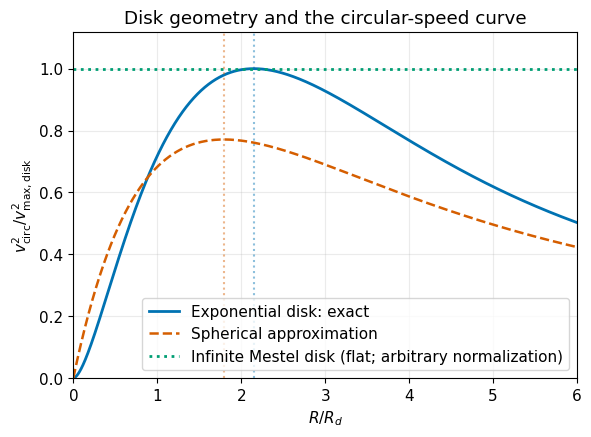

In [8]:
from scipy.special import iv, kv

R_rot = np.linspace(1.0e-4 * Rd, 6.0 * Rd, 4000)
y = R_rot / (2.0 * Rd)

# 修正 Bessel 関数による解析式を評価する（Hankel 積分は直接計算しない）
Bessel_term = iv(0, y) * kv(0, y) - iv(1, y) * kv(1, y)
vc2_disk = 4.0 * np.pi * G * Sigma0 * Rd * y**2 * Bessel_term

# 内包質量の解析解を使い、数値積分の誤差を比較に混ぜない
M_rot = mass_exponential_exact(R_rot, Md, Rd)
vc2_sph = G * M_rot / R_rot

# 各曲線で最大値をとる格子点を求める（補間はしない）
scale_v2 = G * Md / Rd
i_disk = np.argmax(vc2_disk)
i_sph = np.argmax(vc2_sph)
Rpeak_disk = R_rot[i_disk]
Rpeak_sph = R_rot[i_sph]
vc2peak_disk = vc2_disk[i_disk]
vc2peak_sph = vc2_sph[i_sph]

print(f"指数円盤（厳密解）の最大位置: R/Rd = {Rpeak_disk/Rd:.3f}, v_c^2/(GMd/Rd) = {vc2peak_disk/scale_v2:.4f}")
print(f"球対称近似の最大位置:       R/Rd = {Rpeak_sph/Rd:.3f}, v_c^2/(GMd/Rd) = {vc2peak_sph/scale_v2:.4f}")

# 形状比較のため、無限 Mestel 円盤の平坦な曲線を
# 指数円盤の解析式による曲線の最大値で規格化する。
fig, ax = plt.subplots()
ax.plot(R_rot / Rd, vc2_disk / vc2peak_disk, color=OI["blue"], lw=2.0, label="Exponential disk: exact")
ax.plot(R_rot / Rd, vc2_sph / vc2peak_disk, "--", color=OI["vermillion"], lw=1.8, label="Spherical approximation")
ax.axhline(1.0, color=OI["green"], ls=":", lw=2.0, label="Infinite Mestel disk (flat; arbitrary normalization)")
ax.axvline(Rpeak_disk / Rd, color=OI["blue"], alpha=0.45, ls=":")
ax.axvline(Rpeak_sph / Rd, color=OI["vermillion"], alpha=0.45, ls=":")
ax.set_xlabel(r"$R/R_d$")
ax.set_ylabel(r"$v_{\rm circ}^2/v_{\rm max,disk}^2$")
ax.set_title("Disk geometry and the circular-speed curve")
ax.set_xlim(0, 6)
ax.set_ylim(0, 1.12)
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## 演習4：回転曲線の比較と適用条件

1. 指数円盤と球対称近似の最大位置が、それぞれ $R\simeq2.15R_d$ と $R\simeq1.79R_d$ にあることを確認してください。
2. 最大値での $v_{\rm circ}^2/(GM_d/R_d)$ がそれぞれ約 $0.387$ と $0.298$ になることを確認し、Ryden 図6.6の実線・破線と比較してください。
3. $M_{\rm rot}$ に内包質量の解析解を使う理由を説明してください。回転曲線を評価する点を増やしても、二つの曲線の違いはなくならないことを確認してください。
4. 球対称の関係式を一般の円盤へ適用できない理由を、$R$ より外側の質量の寄与に注目して説明してください。
5. 無限 Mestel 円盤で $v_{\rm circ}^2=GM(<R)/R$ が成り立つという一例だけから、一般の円盤にも同じ式を使えると判断してはいけない理由を説明してください。
6. 有限半径で打ち切った Mestel 円盤では、外側の質量の寄与がどう変わるか考えてください。上の図の点線は、有限 Mestel 円盤の計算結果ではありません。
7. **発展：** Ryden 式(6.145)・(6.149) の Hankel 積分を直接数値積分し、修正 Bessel 関数による式と比較してください。振動積分が第1章の滑らかな積分より難しい理由も考えてください。

# まとめ

物理的な題材が変わっても、被積分関数と積分区間を正しく設定すれば、既習の数値積分の実装を再利用できます。ここでは円環の質量要素 $dM=2\pi R\Sigma(R)\,dR$ を使い、解析解との比較と格子収束試験で累積台形則の約2次の収束を確認しました。

数値積分の誤差と、計算領域の外にある質量は別です。また、数値手法を再利用できても、物理の関係式の適用条件まで同じになるわけではありません。回転曲線の比較では解析的な内包質量を用い、球対称近似による違いを数値積分の誤差と切り分けました。Mestel 円盤の比較線は無限円盤の平坦な形を示す任意規格化であり、有限円盤の計算結果ではありません。